# Imports and load data

## Import libraries

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [69]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [70]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_list=[]
for year in range(2006,2011):
    # if year == 2010:
    #     continue
    bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.concat(bulk_data_df_list, ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


Filter rows with no measurements (Cehck why are there such???)

In [71]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [72]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [73]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]
bulk_data_df_split


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,cph_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m
0,74447,240,0.510080,20,36,False,0.170899,"[0.06806687079627374, 0.08033324336606065, 0.0...",0.279615,4.00,...,"[6.943606, 6.6190763, 6.512773, 6.3652906, 6.2...",6.943606,243.479202,"[5.879125e-05, 7.710454e-05, 9.207271e-05, 0.0...","[243.4792, 245.65343, 246.38629, 247.45, 248.2...","[-24.436436, -21.817522, -20.682045, -19.17609...","[1.5473274, 1.6211456, 1.7641913, 1.9469033, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
1,98798,120,0.408134,7,15,True,0.090738,"[0.2040669023990631, 0.2040669023990631, 0.204...",0.204067,2.00,...,"[6.411936, 6.2900915, 6.172365, 6.0538216, 5.9...",6.411936,249.471664,"[0.00025640827, 0.0003735343, 0.00051449396, 0...","[249.47166, 250.43976, 251.37506, 252.26337, 2...","[-19.076298, -16.088455, -13.392471, -11.27006...","[1.738548, 1.7853035, 1.8524339, 1.9644789, 1....","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
2,112249,45,0.435897,0,3,True,0.106998,"[0.5811963081359863, 0.5811963081359863, 0.581...",0.581196,0.75,...,"[2.6627283, 2.5421157, 2.4083316, 2.315197, 2....",2.662728,249.336121,"[0.00028893206, 0.00045705857, 0.0006669469, 0...","[249.33612, 250.38997, 251.5435, 252.31972, 25...","[-25.101063, -22.422428, -19.418106, -18.18285...","[1.8400563, 1.8350871, 1.8396466, 1.863905, 1....","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3,119993,240,0.926610,24,40,False,0.349386,"[0.02587255238800093, 0.17514474505330638, 0.1...",0.502297,4.00,...,"[6.5191355, 6.4039526, 6.281993, 6.159729, 6.0...",6.519135,244.658447,"[0.00022629875, 0.00035418788, 0.0005284226, 0...","[244.65845, 245.49803, 246.41396, 247.32436, 2...","[-18.805279, -15.516134, -13.029601, -10.80267...","[1.7855436, 1.8033655, 1.9213117, 1.9409319, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
4,149677,75,0.703200,16,21,True,0.079823,"[0.5625598430633545, 0.5625598430633545, 0.562...",0.562560,1.25,...,"[4.677273, 4.516191, 4.3961906, 4.2871428, 4.1...",4.677273,233.348282,"[0.00014071807, 0.00014838783, 0.00016950829, ...","[233.34828, 234.48384, 235.50519, 236.43951, 2...","[-30.412498, -30.407381, -28.737778, -25.71194...","[2.0, 2.0, 2.0, 1.984127, 1.9649123, 1.968254,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9092,3016459,240,0.606988,74,90,True,0.111645,"[0.15174710750579834, 0.15174710750579834, 0.1...",0.151747,4.00,...,"[5.991854, 5.7793727, 5.6632557, 5.48973, 5.14...",5.991854,239.861099,"[0.00029364842, 0.00045937902, 0.0006604842, 0...","[239.8611, 241.19537, 241.9347, 243.02045, 245...","[-12.93491, -9.255584, -6.7351446, -5.5270214,...","[1.6543262, 1.627441, 1.6923745, 1.8186798, 1....","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
9093,3016673,465,0.463811,7,38,False,0.185686,"[0.028236934379587453, 0.028983981285186203, 0...",0.151408,7.75,...,"[4.220588, 4.05948, 3.9440336, 3.8213692, 3.70...",4.220588,242.489319,"[3.1700702e-06, 1.0954542e-05, 2.7391176e-05, ...","[242.48932, 243.28241, 243.87073, 244.48207, 2...",

In [74]:
bulk_data_df_split.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'size_hist_km_debug', 'val_ice_frac_hist', 'val_ice_frac_std_hist',
       'val_ice_frac_dev_hist', 'val_pix_claas_if_hist',
       'val_pix_claas_if_st

In [75]:
np.nanmax(np.concat(bulk_data_df_split["iwc_bulk_means"].to_numpy()))

np.float32(-25.417582)

In [76]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    8769
Name: count, dtype: int64

In [77]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [78]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [79]:
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

# Settings

In [13]:
l2_start = 5
l_depth=7
iqr_filter_y=False
iqr_filter_x=True
ind_range = [-3, 4]
rel_times_min = np.array(np.arange(ind_range[0],ind_range[1])*15,dtype=int)
timesteps = [i for i in range(2, -3, -1)]
mean_mode = "log"
confidence_level = 0.90  # 0.68, 0.90, 0.95, 0.99, etc.
n_bootstrap = 5000


# Prepare data

## Optical properties

In [14]:
# def calculate_top_depth(row):
#     tot_thickness = 0
#     small_ext_counter = 0
#     for j, ext in enumerate(row["ext_bulk_means"]):
#         lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
#         tot_thickness += lev_depth*ext
#         if ext<2.0e-4:
#             small_ext_counter+=1
#         if tot_thickness>=0.2:
#             # print(tot_thickness,j*120,small_ext_counter*120)
#             return j*120
#     return None
        
            
# sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [15]:
# (sample["ct_depth"]>600).value_counts()

In [16]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.2):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    return top_idx*120

In [ ]:
# Calculate total optical depth per cloud 
bulk_data_df_split["3km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4)[:l2_start+l_depth*2].all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_ct_depth,axis=1)

In [18]:
(bulk_data_df_split["ct_depth"].isna()).value_counts()

ct_depth
False    7441
True     1328
Name: count, dtype: int64

In [ ]:
(bulk_data_df_split["3km_cot"]<0.2).value_counts()

2km_cot
False    7441
True     1328
Name: count, dtype: int64

In [20]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    7441
True     1328
Name: count, dtype: int64

In [21]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    7441
True     1328
Name: count, dtype: int64

In [22]:
bulk_data_df_split.iloc[0]["val_cth_hist"]

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -

## Check coincidence

In [23]:
ALLOWED_CTH_DEV=1000
def _check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return False
    if type(row["cth_hist"]) == float:
        print("weird")
        return False
    if np.isnan(row["ct_depth"]):
        return False
    cth_deviation = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    if cth_deviation > ALLOWED_CTH_DEV:
        # print(cth_deviation)
        return False
    return True


In [24]:
bulk_data_df_split["val_seviri_coincidence"] = bulk_data_df_split.apply(_check_val_seviri_coincidence,axis=1)

In [25]:
bulk_data_df_split["val_seviri_coincidence"].value_counts()

val_seviri_coincidence
False    4899
True     3870
Name: count, dtype: int64

In [26]:
# print(np.argmax(optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3))
# print(optical_depth_path(bulk_data_filtered.iloc[0])["tau"])

<Figure size 700x500 with 0 Axes>

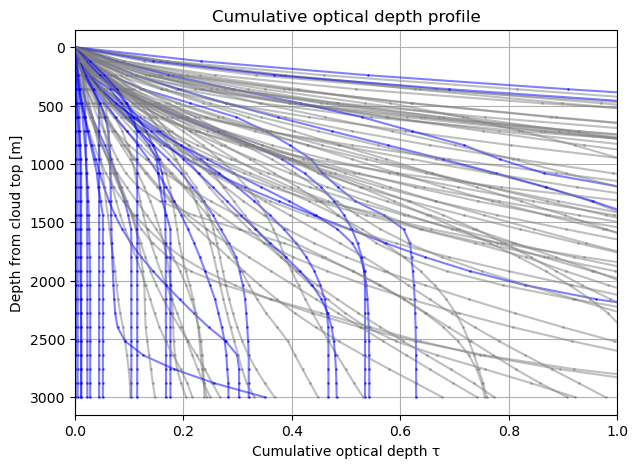

In [27]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

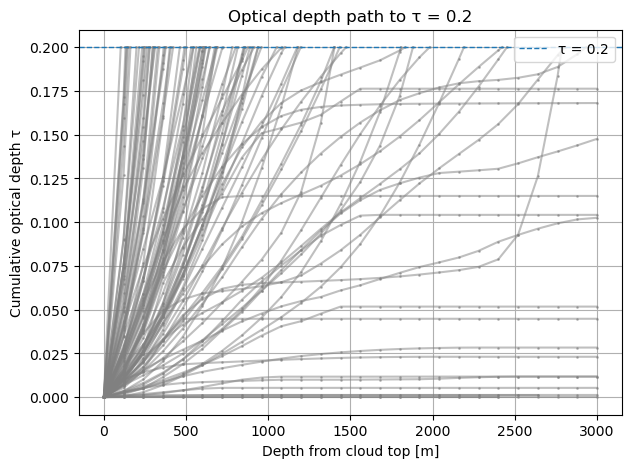

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.2):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.2)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.2")
plt.grid(True)
plt.legend()
plt.show()

## Filter Data

In [29]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lon_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [ ]:
# Filter only for clouds that survive after glaciation
bulk_data_colocated = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]
bulk_data_filtered = bulk_data_colocated[bulk_data_colocated.track_length / pd.Timedelta(minutes=15) > bulk_data_colocated["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["3km_cot"]>0.3]
# Select only one pass where 2 are available
bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# bulk_data_filtered= bulk_data_filtered[~bulk_data_filtered["Cloud type"].isin(["Deep convection", "Cirrus", "Cirrostratus"])]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
# stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
1,98798,120,0.408134,7,15,True,0.090738,"[0.2040669023990631, 0.2040669023990631, 0.204...",0.204067,2.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-12,-180,2.640131,True,480.0,"[maritime, maritime, maritime, maritime, marit...",False
2,112249,45,0.435897,0,3,True,0.106998,"[0.5811963081359863, 0.5811963081359863, 0.581...",0.581196,0.75,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",3,45,1.367798,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True
8,179488,60,0.446666,5,9,False,0.115566,"[0.2788979935899559, 0.6803206860056794, 0.680...",0.482603,1.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",3,45,2.532848,True,600.0,"[maritime, maritime, maritime, maritime, marit...",False
35,260741,90,0.424991,1,7,True,0.053368,"[0.28332748015721637, 0.28332748015721637, 0.2...",0.283327,1.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",10,150,5.290322,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
36,261510,60,0.447988,0,4,True,0.061618,"[0.4479878544807434, 0.4479878544807434, 0.447...",0.447988,1.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",4,60,7.993846,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9069,3009831,360,0.491177,0,24,True,0.085614,"[0.08186286687850952, 0.08186286687850952, 0.0...",0.081863,6.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-11,-165,9.227438,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
9071,3009907,180,0.519143,2,14,True,0.060018,"[0.17304754257202148, 0.17304754257202148, 0.1...",0.173048,3.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-8,-120,5.172707,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
9072,3009920,60,0.567205,0,4,True,0.057134,"[0.5672049522399902, 0.5672049522399902, 0.567...",0.567205,1.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",1,15,5.704307,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
9089,3016057,135,0.558380,17,26,True,0.044564,"[0.24816907776726616, 0.24816907776726616, 0.2...",0.248169,2.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-9,-135,2.731998,True,1080.0,"[maritime, maritime, maritime, maritime, marit...",True


## Z_Meas

In [31]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, ext_meas, iwc_meas

Z_meas, t_meas, ext_meas, iwc_meas = extract_bulk_samples_by_time(bulk_data_filtered)


# Statistics

In [32]:
bulk_data_filtered.to_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Bulk/bulk_data_filtered.parquet")

In [33]:
from scipy.stats import t
import numpy as np

inds = np.arange(ind_range[0], ind_range[1])

# Original vertical levels
y_levels = np.asarray(test_row["bulk_level_offset_top_m"])

# New grouped levels using old level indices

level_groups = [
    list(range(0, l2_start)),
    list(range(l2_start, l2_start+l_depth)),
    list(range(l2_start+l_depth, l2_start+2*l_depth)),
]

group_labels = [
    "levels 0-1",
    "levels 2-9",
    "levels 10-17",
]

n_levels = len(level_groups)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

# Adjust this if your columns correspond to different relative indices
# rel_times_min = np.array([-45, -30, -15, 0, 15, 30, 45])


# level_labels = [
#     "Cloud top",
#     " -560 to -1360 m ",
#     "-1360 to -2160 m ",
# ]

level_labels = [
    "Cloud top",
    f" -{l2_start*120} to -{(l2_start+l_depth)*120} m ",
    f" -{(l2_start+l_depth)*120} to -{(l2_start+2*l_depth)*120} m ",
]



In [34]:
# --------------------------------------------------------------
# Vertical averaging method
#
# "linear": convert dBZ -> Z, average Z, convert back to dBZ
# "log":    arithmetic mean of dBZ values
# --------------------------------------------------------------

if mean_mode not in {"linear", "log"}:
    raise ValueError(
        "mean_mode must be either 'linear' or 'log'"
    )


def calculate_layer_mean_dbz(dbz_block, mode):
    """
    Calculate one vertically averaged dBZ value per cloud.

    Parameters
    ----------
    dbz_block : ndarray
        Shape: clouds x vertical levels.
    mode : {"linear", "log"}
        "linear": average in linear reflectivity space.
        "log": average dBZ values directly.

    Returns
    -------
    ndarray
        One layer-averaged dBZ value per cloud.
    """
    dbz_block = np.asarray(dbz_block, dtype=float)

    valid_counts = np.sum(
        np.isfinite(dbz_block),
        axis=1,
    )

    if mode == "linear":
        linear_z = 10.0 ** (dbz_block / 10.0)

        mean_linear_z = np.divide(
            np.nansum(linear_z, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )

        cloud_values = 10.0 * np.log10(mean_linear_z)

    else:  # mode == "log"
        cloud_values = np.divide(
            np.nansum(dbz_block, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )
    

    return cloud_values


dbZ_grouped_by_ind = {}
cloud_group_values_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = np.asarray(
        Z_meas[ind],
        dtype=float,
    ).copy()

    dbZ[~np.isfinite(dbZ)] = np.nan

    # Shape: clouds x grouped vertical levels
    cloud_group_matrix = np.full(
        (dbZ.shape[0], n_levels),
        np.nan,
    )

    grouped_dbZ = []

    for i, group in enumerate(level_groups):
        cloud_values = calculate_layer_mean_dbz(
            dbZ[:, group],
            mode=mean_mode,
        )

        # Preserve row alignment for cloud-level bootstrapping
        cloud_group_matrix[:, i] = cloud_values

        # Finite sample used for statistics
        finite_values = cloud_values[
            np.isfinite(cloud_values)
        ]

        grouped_dbZ.append(finite_values)

        if len(finite_values) >= 1:
            mean_map[i, col] = np.mean(finite_values)
            n_map[i, col] = len(finite_values)

        if len(finite_values) >= 2:
            std_map[i, col] = np.std(
                finite_values,
                ddof=1,
            )

    dbZ_grouped_by_ind[ind] = grouped_dbZ
    cloud_group_values_by_ind[ind] = cloud_group_matrix

sem_map = std_map / np.sqrt(n_map)

In [35]:
dbZ.shape

(40, 25)

In [36]:
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)

# ------------------------------------------------------------
# 1. Outlier remover
# ------------------------------------------------------------
def remove_outliers_iqr(x, k=1.5):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]

for j, ind in enumerate(inds):
    x_groups = dbZ_grouped_by_ind[ind]

    other_inds = [k for k in inds if k != ind]

    for i in range(n_levels):
        x = x_groups[i]
        x = x[np.isfinite(x)]

        # Pool the same grouped level from all other time indices
        y = np.concatenate([
            dbZ_grouped_by_ind[k][i]
            for k in other_inds
        ])

        y = y[np.isfinite(y)]

        n_y_raw = len(y)

        # Remove outliers only from y
        if iqr_filter_y:
            y = remove_outliers_iqr(y, k=1.5)
        if iqr_filter_x:
            x=remove_outliers_iqr(x,k=1.5)

        if len(x) < 2 or len(y) < 2:
            continue

        mx, my = np.mean(x), np.mean(y)
        vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
        nx, ny = len(x), len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den

        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = ny

In [37]:
def calculate_pooled_deviations(cloud_arrays, inds, n_levels):
    """Deviation of each time mean from all other clouds pooled."""

    n_times = len(inds)
    deviations = np.full((n_levels, n_times), np.nan)

    for j, ind in enumerate(inds):
        other_inds = [k for k in inds if k != ind]

        for i in range(n_levels):
            x = cloud_arrays[ind][:, i]
            x = x[np.isfinite(x)]

            y = np.concatenate([
                cloud_arrays[k][:, i]
                for k in other_inds
            ])
            y = y[np.isfinite(y)]

            if len(x) > 0 and len(y) > 0:
                deviations[i, j] = (
                    np.mean(x) - np.mean(y)
                )

    return deviations

In [38]:
rng = np.random.default_rng(42)

index_bootstrap = np.full(
    (n_bootstrap, n_times - 1),
    np.nan,
)

for b in range(n_bootstrap):
    bootstrap_arrays = {}

    for ind in inds:
        values = cloud_group_values_by_ind[ind]
        n_clouds = values.shape[0]

        # Resample complete cloud rows
        sample_indices = rng.integers(
            0,
            n_clouds,
            size=n_clouds,
        )

        bootstrap_arrays[ind] = values[sample_indices]

    bootstrap_deviations = calculate_pooled_deviations(
        bootstrap_arrays,
        inds,
        n_levels,
    )

    index_bootstrap[b] = (
        bootstrap_deviations[1, :-1]
        + bootstrap_deviations[2, 1:]
    )

In [39]:

if not 0 < confidence_level < 1:
    raise ValueError("confidence_level must be between 0 and 1")

alpha = 1.0 - confidence_level

lower_percentile = 100.0 * alpha / 2.0
upper_percentile = 100.0 * (1.0 - alpha / 2.0)

sedimentation_index = (
    dev_vs_others_map[1, :-1] +
    dev_vs_others_map[2, 1:]
)

(
    sedimentation_index_ci_low,
    sedimentation_index_ci_high,
) = np.nanpercentile(
    index_bootstrap,
    [lower_percentile, upper_percentile],
    axis=0,
)

# Correlation data

In [40]:
corr_peak_ci = pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/IF_autocorrelation_values.parquet")

In [82]:
corr_peak_ci

,rel_ind,rel_time_min,corr_with_peak,ci_low,ci_high,n_clouds
0,-8,-120,-0.045333,-0.050407,-0.040449,130009
1,-7,-105,-0.023465,-0.028369,-0.019104,151071
2,-6,-90,0.003411,-0.001878,0.007911,177973
3,-5,-75,0.036599,0.031798,0.040474,212163
4,-4,-60,0.069449,0.065280,0.072961,256928
5,-3,-45,0.112179,0.107647,0.115964,316644
6,-2,-30,0.154007,0.149817,0.158023,347634
7,-1,-15,0.302989,0.299130,0.307376,347634
8,0,0,1.000000,1.000000,1.000000,347634
9,1,15,0.407406,0.401695,0.413475,208326


# Bulk Plot

In [41]:
import matplotlib.gridspec as gridspec
import cmcrameri
import matplotlib.font_manager as fm
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm

In [42]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# cmcrameri.cm.show_cmaps()



In [43]:
classifiacation_palette = cmcrameri.cm.actonS.colors[[i for i in range(10) if i != 1],:]

Bulk publication figure

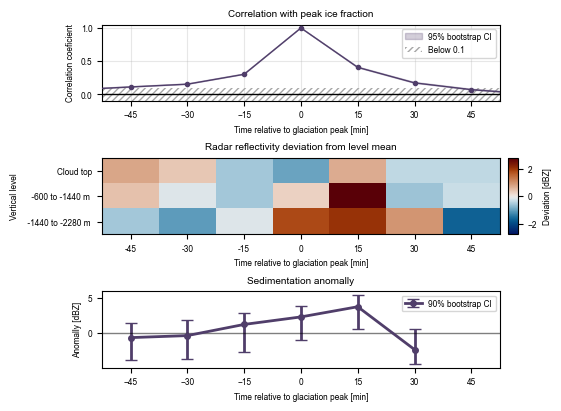

In [44]:

# fig = plt.figure(figsize=(6.69291, 6.69291*3.504/5.501), constrained_layout=True) 170 mm
fig = plt.figure(figsize=(5.501, 4), constrained_layout=True)#5.501*3.504/5.501), constrained_layout=True)
gs = gridspec.GridSpec(3, 3,height_ratios=[1, 1,1], width_ratios=[1,1,0.05],figure=fig)#,hspace=1.2, wspace=0.3)#,
ax_heat = fig.add_subplot(gs[1, :2])
ax_top_cb = fig.add_subplot(gs[1, 2])
ax_anom = fig.add_subplot(gs[2, :2])
ax_corr = fig.add_subplot(gs[0, :2])


# Common axes formatting
for ax in (ax_heat,):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)
    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)
    ax.set_ylabel("Vertical level")
    ax.set_xlabel("Time relative to glaciation peak [min]")

vmax = np.nanmax(np.abs(dev_vs_others_map))



ax_heat.set_title("Radar reflectivity deviation from level mean")

im1 = ax_heat.imshow(
    dev_vs_others_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax),
    origin="upper",
)

cbar = fig.colorbar(im1, cax=ax_top_cb)
cbar.set_label("Deviation [dBZ]")  # Adjust units/label as needed

index_times = rel_times_min[:-1]

ci_percent = 100 * confidence_level
# ax_anom
ax_anom.errorbar(
    index_times,
    sedimentation_index,
    yerr=np.vstack([
        np.maximum(
            sedimentation_index - sedimentation_index_ci_low,
            0,
        ),
        np.maximum(
            sedimentation_index_ci_high - sedimentation_index,
            0,
        ),
    ]),
    marker="o",
    linewidth=2,
    markersize=4,
    capsize=4,
    label=f"{ci_percent:g}% bootstrap CI",
    color=classifiacation_palette[4]
)

ax_anom.legend()
ax_anom.axhline(
    0,
    color="k",
    linewidth=1,
    alpha=0.5,
)

ax_anom.set_xticks(rel_times_min)
ax_anom.set_xlabel("Time relative to glaciation peak [min]")
ax_anom.set_ylabel("Anomally [dBZ]")
ax_anom.set_title("Sedimentation anomally")
ax_anom.set_xlim(-45-7.5,+45+7.5)
ax_anom.legend(loc="upper right")


ax_corr.plot(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["corr_with_peak"],
    marker="o",
    markersize=3,
    linewidth=1,
    # label="Correlation with peak",
    zorder=3,
    color=classifiacation_palette[4]
)

ax_corr.fill_between(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["ci_low"],
    corr_peak_ci["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
    zorder=2,
    color=classifiacation_palette[4]
)

# ax_corr.axvline(
#     0,
#     color="k",
#     linestyle="--",
#     linewidth=1,
#     label="Glaciation peak",
#     zorder=4,
# )

ax_corr.axhline(
    0,
    color="k",
    linewidth=1,
    zorder=4,
)

# Hatched region: correlation below 0.1
ax_corr.axhspan(
    -0.1,
    0.1,
    facecolor="none",
    edgecolor="0.65",
    hatch="/////",
    linewidth=0,
    zorder=0,
    label="Below 0.1",
)

# Label every 15-minute sample
xmin = corr_peak_ci["rel_time_min"].min()
xmax = corr_peak_ci["rel_time_min"].max()

xticks = np.arange(
    np.floor(xmin / 15) * 15,
    np.ceil(xmax / 15) * 15 + 15,
    15,
)

ax_corr.set_xticks(xticks)
ax_corr.set_xlim(xmin, xmax)
ax_corr.set_xlim(-45-7.5,45+7.5)


ax_corr.set_xlabel("Time relative to glaciation peak [min]")
ax_corr.set_ylabel("Correlation coeficient")
ax_corr.set_title("Correlation with peak ice fraction")
ax_corr.set_ylim(-0.1, 1.05)

ax_corr.grid(alpha=0.3)
ax_corr.legend()


fig.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/Bulk_figure.pdf",
    format="pdf",
    dpi=300
)

## Bias-source publication figure


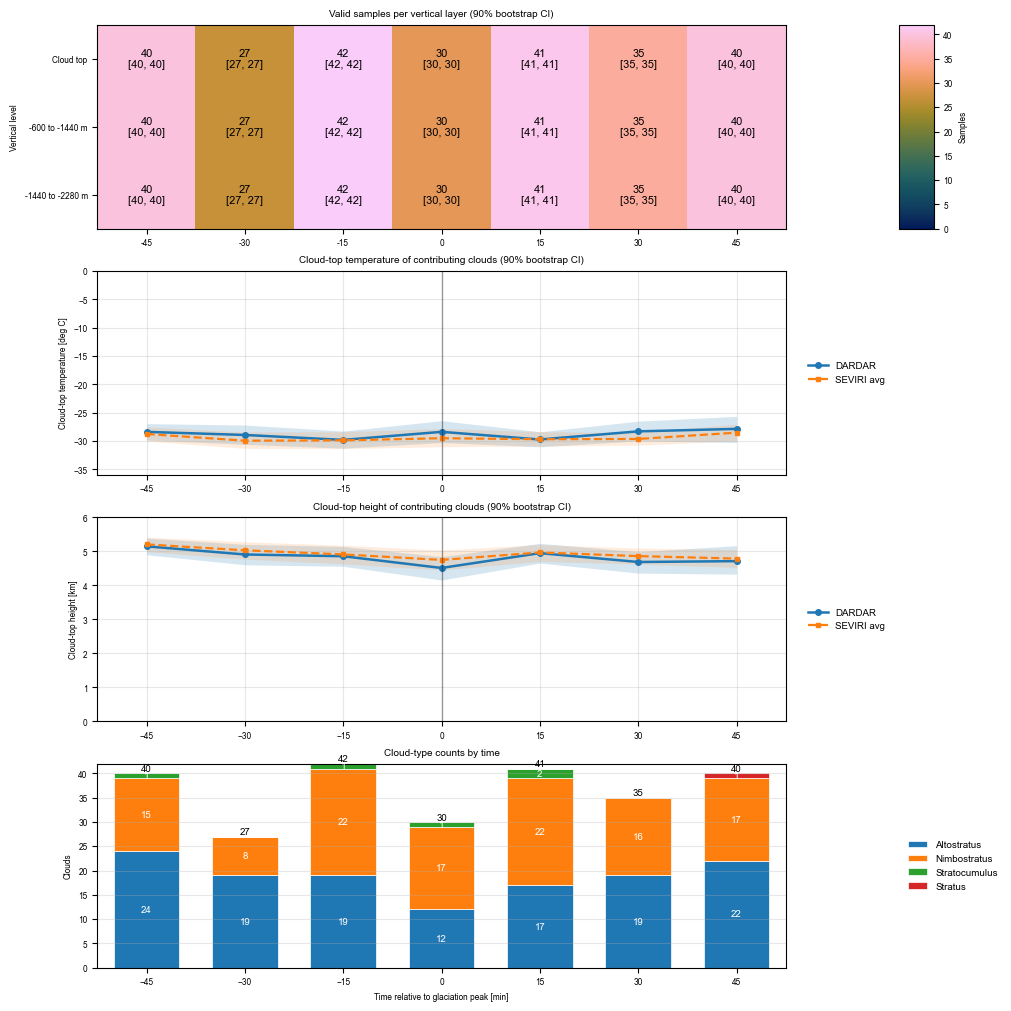

<Figure size 640x480 with 0 Axes>

In [45]:
# Produces the three-row bias-source figure from bulk_data_filtered.parquet
%run /Volumes/University_stuff/Code_Projects/MSGI/plotting/Bulk/bias_sources_publication_figure.py


In [46]:
bulk_data_filtered["ct_depth"].mean()

np.float64(546.2838915470494)

In [47]:
bulk_data_filtered["ct_depth"].mean()/120

np.float64(4.552365762892078)

In [48]:
bulk_data_filtered["Cloud type"].value_counts()

Cloud type
Altostratus      957
Nimbostratus     847
Stratocumulus     61
Stratus           16
Name: count, dtype: int64

In [49]:
n_y_clean_map

array([[215., 228., 213., 225., 214., 220., 215.],
       [215., 228., 213., 225., 214., 220., 215.],
       [215., 228., 213., 225., 214., 220., 215.]])

In [50]:
n_x_map

array([[40., 26., 42., 30., 39., 34., 39.],
       [40., 27., 40., 28., 39., 34., 40.],
       [40., 26., 41., 26., 41., 35., 40.]])

In [51]:
bulk_data_filtered["ct_depth"].mean()/120

np.float64(4.552365762892078)

In [52]:
bulk_data_filtered.iloc[0]["Z_bulk_means"]

array([-19.076298 , -16.088455 , -13.392471 , -11.270064 ,  -9.405037 ,
        -7.7233386,  -6.2596865,  -5.0125785,  -3.7417407,  -2.638119 ,
        -2.0838084,  -2.0461843,  -2.5445316,  -3.3624763,  -4.716188 ,
        -5.942751 ,  -7.5593486,  -9.166061 , -10.989412 , -12.525781 ,
       -14.48649  , -16.871851 , -18.898174 , -21.166367 , -23.485615 ],
      dtype=float32)

In [53]:
# ------------------------------------------------------------
# Vertical deviations:
# each level versus all other levels at the same time
# ------------------------------------------------------------
dev_vs_other_levels_map = np.full_like(mean_map, np.nan)
p_welch_vertical_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    level_samples = dbZ_grouped_by_ind[ind]

    for i in range(n_levels):
        # Reflectivity values at the current level and time
        x = np.asarray(level_samples[i], dtype=float)
        x = x[np.isfinite(x)]

        # Pool all other vertical levels at the same time
        other_levels = [
            np.asarray(level_samples[k], dtype=float)
            for k in range(n_levels)
            if k != i
        ]

        if not other_levels:
            continue

        y = np.concatenate(other_levels)
        y = y[np.isfinite(y)]

        # Consistent with your time-direction calculation:
        # remove outliers only from the reference sample
        if iqr_filter_y:
            y = remove_outliers_iqr(y, k=1.5)
        if iqr_filter_x:
            x=remove_outliers_iqr(x,k=1.5)

        if len(x) < 2 or len(y) < 2:
            continue

        mx = np.mean(x)
        my = np.mean(y)

        vx = np.var(x, ddof=1)
        vy = np.var(y, ddof=1)

        nx = len(x)
        ny = len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        dev_vs_other_levels_map[i, j] = dev

        if se <= 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = (
            ((vx / nx) ** 2) / (nx - 1)
            + ((vy / ny) ** 2) / (ny - 1)
        )

        if df_den <= 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den
        p_welch_vertical_map[i, j] = 2 * t.sf(np.abs(tval), df)

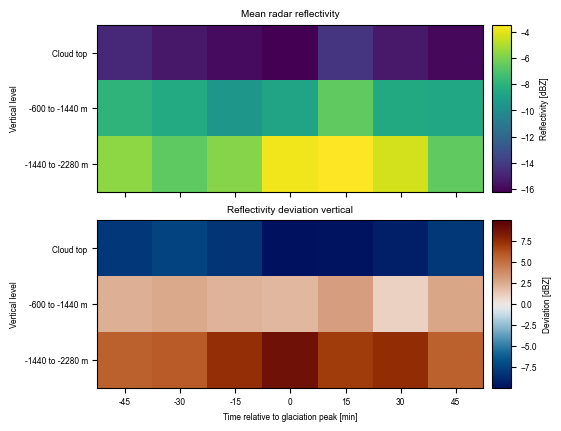

In [54]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib import gridspec
import matplotlib.pyplot as plt
import numpy as np

fig_vertical = plt.figure(
    figsize=(5.501, 4.2),
    constrained_layout=True,
)

gs_vertical = gridspec.GridSpec(
    2,
    2,
    figure=fig_vertical,
    height_ratios=[1, 1],
    width_ratios=[1, 0.05],
)

ax_absolute = fig_vertical.add_subplot(gs_vertical[0, 0])
ax_absolute_cb = fig_vertical.add_subplot(gs_vertical[0, 1])

ax_vertical_dev = fig_vertical.add_subplot(gs_vertical[1, 0])
ax_vertical_dev_cb = fig_vertical.add_subplot(gs_vertical[1, 1])

# ------------------------------------------------------------
# Absolute reflectivity
# ------------------------------------------------------------
im_absolute = ax_absolute.imshow(
    mean_map,
    aspect="auto",
    cmap="viridis",
    origin="upper",
)

cbar_absolute = fig_vertical.colorbar(
    im_absolute,
    cax=ax_absolute_cb,
)
cbar_absolute.set_label("Reflectivity [dBZ]")

ax_absolute.set_title("Mean radar reflectivity")

# ------------------------------------------------------------
# Vertical deviations
# ------------------------------------------------------------
vertical_vmax = np.nanmax(
    np.abs(dev_vs_other_levels_map)
)

if not np.isfinite(vertical_vmax) or vertical_vmax == 0:
    vertical_vmax = 1.0

im_vertical_dev = ax_vertical_dev.imshow(
    dev_vs_other_levels_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-vertical_vmax,
        vcenter=0,
        vmax=vertical_vmax,
    ),
    origin="upper",
)

cbar_vertical = fig_vertical.colorbar(
    im_vertical_dev,
    cax=ax_vertical_dev_cb,
)
cbar_vertical.set_label("Deviation [dBZ]")

ax_vertical_dev.set_title(
    "Reflectivity deviation vertical"
)

# ------------------------------------------------------------
# Common formatting
# ------------------------------------------------------------
for ax in (ax_absolute, ax_vertical_dev):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)

    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)

    ax.set_ylabel("Vertical level")

# Avoid repeating x-axis labels on the upper panel
ax_absolute.tick_params(
    axis="x",
    labelbottom=False,
)

ax_vertical_dev.set_xlabel(
    "Time relative to glaciation peak [min]"
)

fig_vertical.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/"
    "Reflectivity_vertical_deviation.pdf",
    format="pdf",
    dpi=300,
)

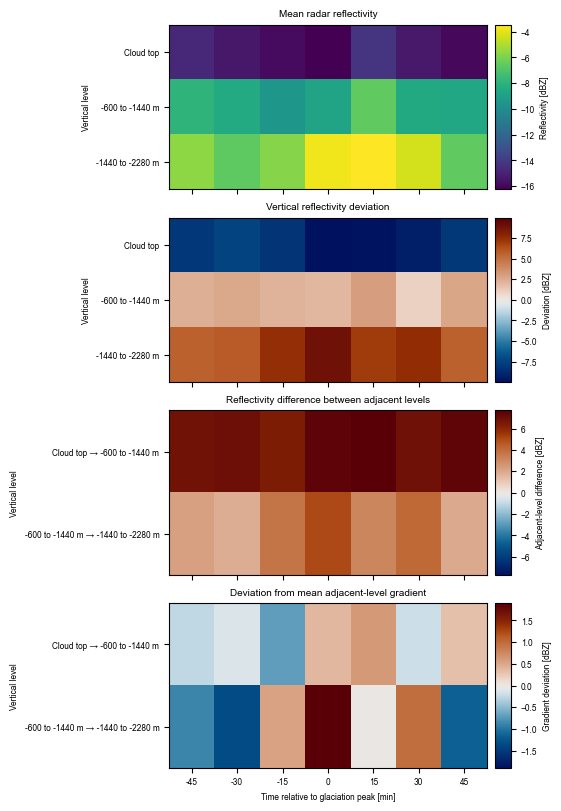

In [55]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib import gridspec
import matplotlib.pyplot as plt
import numpy as np
from cmcrameri import cm


def symmetric_limit(data, fallback=1.0):
    """Return a finite, nonzero symmetric color limit."""
    finite_values = np.asarray(data)[np.isfinite(data)]

    if finite_values.size == 0:
        return fallback

    limit = np.max(np.abs(finite_values))

    if limit == 0:
        return fallback

    return limit


# ------------------------------------------------------------
# Calculate vertical gradients
# ------------------------------------------------------------

# Difference between consecutive vertical levels:
# gradient[i] = reflectivity[i + 1] - reflectivity[i]
vertical_gradient_map = np.diff(
    mean_map,
    axis=0,
)

gradient_level_labels = [
    f"{level_labels[i]} → {level_labels[i + 1]}"
    for i in range(len(level_labels) - 1)
]

# Mean gradient through time for each adjacent-level pair
mean_vertical_gradient = np.nanmean(
    vertical_gradient_map,
    axis=1,
    keepdims=True,
)

# Deviation from the time-mean gradient of each level pair
gradient_deviation_map = (
    vertical_gradient_map - mean_vertical_gradient
)


# ------------------------------------------------------------
# Create figure and axes
# ------------------------------------------------------------
fig_vertical = plt.figure(
    figsize=(5.501, 8.0),
    constrained_layout=True,
)

gs_vertical = gridspec.GridSpec(
    4,
    2,
    figure=fig_vertical,
    height_ratios=[1, 1, 1, 1],
    width_ratios=[1, 0.05],
)

ax_absolute = fig_vertical.add_subplot(
    gs_vertical[0, 0]
)
ax_absolute_cb = fig_vertical.add_subplot(
    gs_vertical[0, 1]
)

ax_vertical_dev = fig_vertical.add_subplot(
    gs_vertical[1, 0]
)
ax_vertical_dev_cb = fig_vertical.add_subplot(
    gs_vertical[1, 1]
)

ax_vertical_gradient = fig_vertical.add_subplot(
    gs_vertical[2, 0]
)
ax_vertical_gradient_cb = fig_vertical.add_subplot(
    gs_vertical[2, 1]
)

ax_gradient_dev = fig_vertical.add_subplot(
    gs_vertical[3, 0]
)
ax_gradient_dev_cb = fig_vertical.add_subplot(
    gs_vertical[3, 1]
)


# ------------------------------------------------------------
# Absolute reflectivity
# ------------------------------------------------------------
im_absolute = ax_absolute.imshow(
    mean_map,
    aspect="auto",
    cmap="viridis",
    origin="upper",
)

cbar_absolute = fig_vertical.colorbar(
    im_absolute,
    cax=ax_absolute_cb,
)
cbar_absolute.set_label(
    "Reflectivity [dBZ]"
)

ax_absolute.set_title(
    "Mean radar reflectivity"
)


# ------------------------------------------------------------
# Vertical reflectivity deviations
# ------------------------------------------------------------
vertical_vmax = symmetric_limit(
    dev_vs_other_levels_map
)

im_vertical_dev = ax_vertical_dev.imshow(
    dev_vs_other_levels_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-vertical_vmax,
        vcenter=0,
        vmax=vertical_vmax,
    ),
    origin="upper",
)

cbar_vertical = fig_vertical.colorbar(
    im_vertical_dev,
    cax=ax_vertical_dev_cb,
)
cbar_vertical.set_label(
    "Deviation [dBZ]"
)

ax_vertical_dev.set_title(
    "Vertical reflectivity deviation"
)


# ------------------------------------------------------------
# Gradient between adjacent vertical levels
# ------------------------------------------------------------
gradient_vmax = symmetric_limit(
    vertical_gradient_map
)

im_vertical_gradient = ax_vertical_gradient.imshow(
    vertical_gradient_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-gradient_vmax,
        vcenter=0,
        vmax=gradient_vmax,
    ),
    origin="upper",
)

cbar_gradient = fig_vertical.colorbar(
    im_vertical_gradient,
    cax=ax_vertical_gradient_cb,
)
cbar_gradient.set_label(
    "Adjacent-level difference [dBZ]"
)

ax_vertical_gradient.set_title(
    "Reflectivity difference between adjacent levels"
)


# ------------------------------------------------------------
# Deviations from the mean gradient at each level pair
# ------------------------------------------------------------
gradient_dev_vmax = symmetric_limit(
    gradient_deviation_map
)

im_gradient_dev = ax_gradient_dev.imshow(
    gradient_deviation_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-gradient_dev_vmax,
        vcenter=0,
        vmax=gradient_dev_vmax,
    ),
    origin="upper",
)

cbar_gradient_dev = fig_vertical.colorbar(
    im_gradient_dev,
    cax=ax_gradient_dev_cb,
)
cbar_gradient_dev.set_label(
    "Gradient deviation [dBZ]"
)

ax_gradient_dev.set_title(
    "Deviation from mean adjacent-level gradient"
)


# ------------------------------------------------------------
# Common axis formatting
# ------------------------------------------------------------
all_axes = (
    ax_absolute,
    ax_vertical_dev,
    ax_vertical_gradient,
    ax_gradient_dev,
)

for ax in all_axes:
    ax.set_xticks(
        np.arange(len(rel_times_min))
    )
    ax.set_xticklabels(
        rel_times_min
    )
    ax.set_ylabel(
        "Vertical level"
    )

# The first two panels use the original vertical levels
for ax in (
    ax_absolute,
    ax_vertical_dev,
):
    ax.set_yticks(
        np.arange(len(level_labels))
    )
    ax.set_yticklabels(
        level_labels
    )

# The gradient panels use adjacent-level pairs
for ax in (
    ax_vertical_gradient,
    ax_gradient_dev,
):
    ax.set_yticks(
        np.arange(len(gradient_level_labels))
    )
    ax.set_yticklabels(
        gradient_level_labels
    )

# Display time labels only on the bottom panel
for ax in all_axes[:-1]:
    ax.tick_params(
        axis="x",
        labelbottom=False,
    )

ax_gradient_dev.set_xlabel(
    "Time relative to glaciation peak [min]"
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
fig_vertical.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/"
    "Reflectivity_vertical_deviation.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [56]:
vertical_gradient_map = mean_map[1:] - mean_map[:-1]
vertical_gradient_map.mean(axis=0)

array([4.54483706, 4.38143492, 5.03567105, 6.24944637, 5.40761199,
       5.49971235, 4.69050875])

# IF plot

In [57]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]


In [58]:
# dd_data_list = []
# for year in range(2007,2009):
#     dd_data_list.append(pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02/glaciations_with_bulk_data_V3_1_2007.parquet"))
df_glac_dd = bulk_data_colocated

In [59]:
def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

def get_if_glac_peak_same_cloud(row):
    if_hist = row["val_ice_frac_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if_hist = row["val_pix_claas_if_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

def get_dd_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["val_ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        if if_hist[row["Glac_peak_ind"]-idx]>0:
            return row["cph_bulk_means"][0].mean()-1
        return np.nan
    return np.nan


def check_cph_validity(row: pd.Series):   
    ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if np.isnan(int(row["val_ice_frac_hist"][ind])):
        raise TypeError("Weird error ") 
    return row["cph_bulk_means"][0].mean()-1 - row["val_ice_frac_hist"][ind]

In [60]:
bulk_data_df_split.apply(check_cph_validity,axis=1).mean()

np.float64(0.002804261124650708)

(array([2.000e+00, 2.000e+00, 1.000e+01, 3.700e+01, 3.020e+02, 6.560e+03,
        1.659e+03, 1.530e+02, 3.900e+01, 1.000e+00]),
 array([-0.82142854, -0.67928569, -0.53714285, -0.395     , -0.25285716,
        -0.11071432,  0.03142853,  0.17357137,  0.31571422,  0.45785706,
         0.5999999 ]),
 <BarContainer object of 10 artists>)

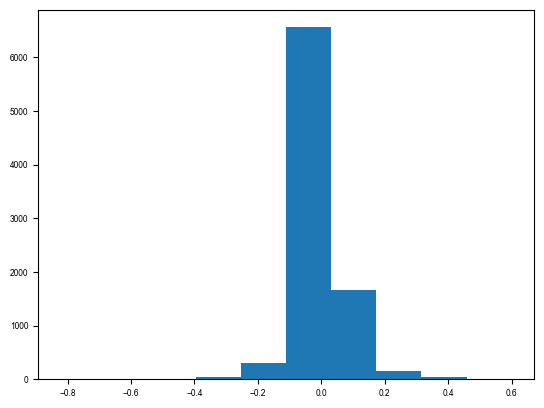

In [61]:
plt.hist(bulk_data_df_split.apply(check_cph_validity,axis=1))

In [62]:
np.nanmean(np.concat(bulk_data_colocated["cph_bulk_means"].to_numpy()).reshape(bulk_data_colocated.shape[0],25),axis=0)


array([1.7485601, 1.769196 , 1.8273344, 1.891936 , 1.9158106, 1.9318722,
       1.9409796, 1.9481449, 1.9526986, 1.9547105, 1.9564147, 1.9571512,
       1.9570572, 1.9573542, 1.9554582, 1.9536383, 1.9510871, 1.9467484,
       1.9421085, 1.9380995, 1.9288272, 1.9184953, 1.911126 , 1.9031578,
       1.8966271], dtype=float32)

In [63]:
bulk_data_colocated.iloc[10]["cph_bulk_means"]

array([2.       , 2.       , 2.       , 1.9799107, 1.9799107, 1.9598215,
       1.9799107, 1.9799107, 1.9799107, 1.9799107, 2.       , 2.       ,
       2.       , 2.       , 2.       , 2.       , 2.       , 2.       ,
       2.       , 2.       , 2.       , 2.       , 2.       , 2.       ,
       2.       ], dtype=float32)

In [64]:
for pre_peak_idx in range(-5, 5):
    # df_glac_mod[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #     get_seviri_pre_peak_if,
    #     axis=1,
    #     args=(pre_peak_idx,)
    # )
    df_glac_dd[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_dd_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    # df_glac_mod[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #         get_dd_pre_peak_if,
    #         axis=1,
    #         args=(pre_peak_idx,)
    #     )
    

In [65]:
df_glac_dd["val_1_prepeak_if"].dropna()

91      0.625627
160     0.964286
275     0.955523
324     0.907924
386     0.568300
          ...   
8905    0.830870
8977    0.512565
9046    0.926226
9081    0.613636
9087    0.975399
Name: val_1_prepeak_if, Length: 112, dtype: float64

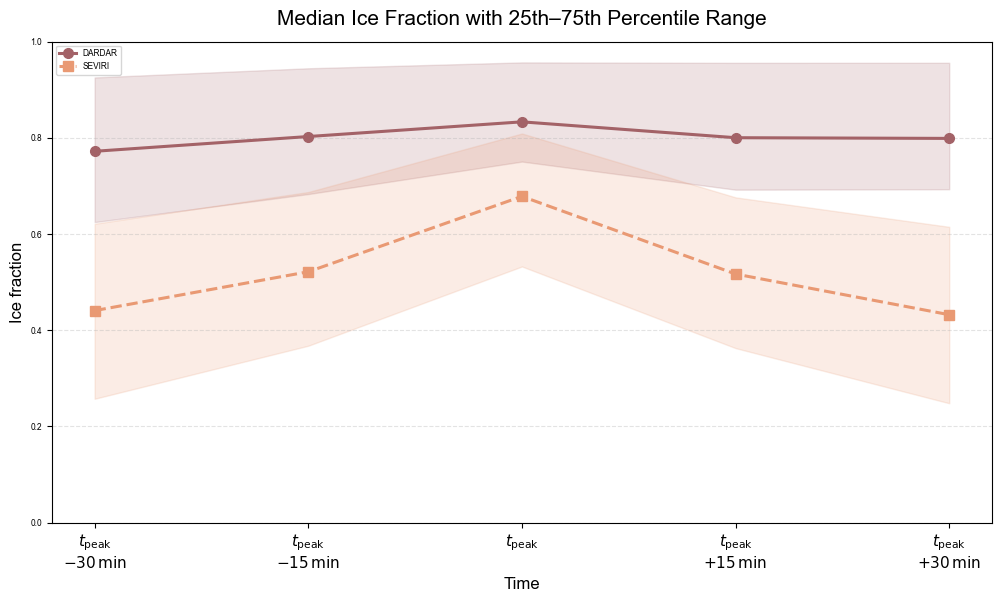

In [66]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order


# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
# modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

# x_labels = [
#     # r"$t_{\mathrm{peak}}-45\mathrm{min}$",
#     r"$t_{\mathrm{peak}}-30\mathrm{min}$",
#     r"$t_{\mathrm{peak}}-15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}$",
#     r"$t_{\mathrm{peak}}+15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}+30\mathrm{min}$",
#     # r"$t_{\mathrm{peak}}+45\mathrm{min}$",
# ]

x_labels = [
    "$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$",
    "$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$",
]


def clean_vals(series):
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.percentile(vals, 50)
    med = np.nanmean(vals)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
# modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col in zip(dardar_cols, seviri_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_dd[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    # mod_vals = clean_vals(df_glac_mod[mod_col])
    # q25, med, q75 = median_q25_q75(mod_vals)
    # modis_q25.append(q25)
    # modis_med.append(med)
    # modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

# modis_q25 = np.array(modis_q25)
# modis_med = np.array(modis_med)
# modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR", color = color_dd
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI", color = color_sev
)

# line3, = plt.plot(
#     x, modis_med,
#     marker="^", linestyle=":", linewidth=2.2, markersize=7,
#     label="MODIS", color = color_mod
# )

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

# plt.fill_between(
#     x, modis_q25, modis_q75,
#     color=line3.get_color(), alpha=0.18
# )

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
# plt.ylim(0.8)
plt.show()

In [67]:
eps=1e-4
for col in dardar_cols:
    raw = pd.to_numeric(df_glac_dd[col], errors="coerce").dropna()

    first = raw[raw.between(0, 1)]
    second = raw[raw.between(-eps, 1 + eps)]

    print(
        col,
        "above 1:", (raw > 1).sum(),
        "first n:", len(first),
        "first fraction:", (first >= 0.80).mean(),
        "second n:", len(second),
        "second fraction:", (second > 0.85).mean(),
    )

val_2_prepeak_if above 1: 0 first n: 129 first fraction: 0.5658914728682171 second n: 129 second fraction: 0.46511627906976744
val_1_prepeak_if above 1: 0 first n: 112 first fraction: 0.6071428571428571 second n: 112 second fraction: 0.5357142857142857
val_0_prepeak_if above 1: 0 first n: 108 first fraction: 0.7037037037037037 second n: 108 second fraction: 0.6296296296296297
val_-1_prepeak_if above 1: 0 first n: 77 first fraction: 0.5844155844155844 second n: 77 second fraction: 0.5454545454545454
val_-2_prepeak_if above 1: 0 first n: 76 first fraction: 0.6578947368421053 second n: 76 second fraction: 0.5921052631578947
